In [1]:
# Reload edited package modules automatically when rerunning cells.
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
from pathlib import Path
import sys

# Support kernels started in either the repository root or notebooks folder.
project_root = Path.cwd().resolve()
if not (project_root / 'uuv_mission').is_dir():
    project_root = project_root.parent
if not (project_root / 'uuv_mission').is_dir():
    raise FileNotFoundError('Start the notebook from the repository root or notebooks folder.')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Simulate closed-loop
Load the supplied mission and run it with a PD controller. Adjust the gains below to explore tracking performance. The controller update period matches the submarine time step.

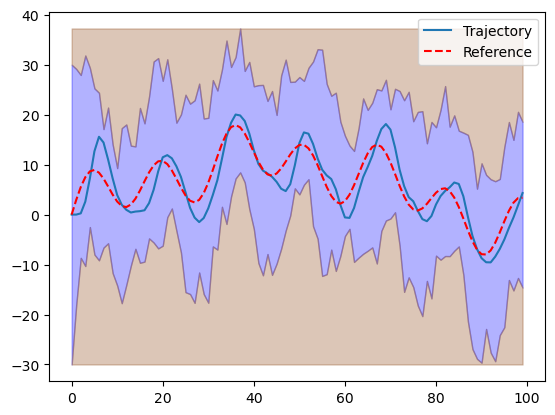

In [ ]:
import numpy as np
from uuv_mission.control import PDController
from uuv_mission.dynamic import Submarine, ClosedLoop, Mission

sub = Submarine()
controller = PDController(Kp=0.15, Kd=0.6)
closed_loop = ClosedLoop(sub, controller)
mission = Mission.from_csv(project_root / 'data' / 'mission.csv')

# Use a fixed seed so rerunning the demo produces the same disturbances.
np.random.seed(42)
trajectory = closed_loop.simulate_with_random_disturbances(mission)
trajectory.plot_completed_mission(mission)

Run with PID Controller. This works because PIDController is a subclass of PDController.

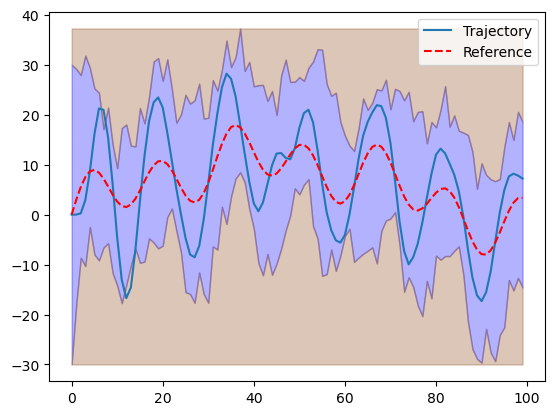

In [13]:
from uuv_mission.control import PIDController

sub = Submarine()
controller = PIDController(Kp=0.15, Kd=0.6, Ki=0.1)
closed_loop = ClosedLoop(sub, controller)
mission = Mission.from_csv(project_root / 'data' / 'mission.csv')

# Use a fixed seed so rerunning the demo produces the same disturbances.
np.random.seed(42)
trajectory = closed_loop.simulate_with_random_disturbances(mission)
trajectory.plot_completed_mission(mission)